In [2]:
# Plant Disease Detection using CNN - Complete Working Code
# SAIA 2133 - Computer Vision Final Project
# Step-by-Step Implementation Guide

"""
PROJECT: Plant Disease Detection for Agriculture
DATASET: PlantVillage - Tomato Diseases
CLASSES: 3 (Healthy, Early Blight, Late Blight)
MODELS: Custom CNN + Transfer Learning (EfficientNetB0)
"""

'\nPROJECT: Plant Disease Detection for Agriculture\nDATASET: PlantVillage - Tomato Diseases\nCLASSES: 3 (Healthy, Early Blight, Late Blight)\nMODELS: Custom CNN + Transfer Learning (EfficientNetB0)\n'

In [3]:
# ============================================================================
# STEP 1: INSTALL AND IMPORT LIBRARIES
# ============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
import shutil
from pathlib import Path
import kagglehub
import json
import random

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0,EfficientNetB4, ResNet50, MobileNetV3Large
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras import mixed_precision

# Metrics
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("="*70)
print("PLANT DISEASE DETECTION - SETUP COMPLETE")
print("="*70)
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {len(tf.config.list_physical_devices('GPU')) > 0}")
print(f"GPU Devices: {tf.config.list_physical_devices('GPU')}")
gpus = tf.config.list_physical_devices('GPU') 
if gpus: 
    for gpu in gpus: 
        tf.config.experimental.set_memory_growth(gpu, True) 
    print("✅ GPU memory growth enabled") # Enable mixed precision (if GPU supports Tensor Cores) 
mixed_precision.set_global_policy('mixed_float16') 
print("✅ Mixed precision enabled") 
# Enable XLA compiler 
tf.config.optimizer.set_jit(True) 
print("✅ XLA compiler enabled")


2026-01-12 11:05:56.595580: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-12 11:05:57.448410: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-12 11:06:00.360222: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


PLANT DISEASE DETECTION - SETUP COMPLETE
TensorFlow Version: 2.20.0
GPU Available: True
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ GPU memory growth enabled
✅ Mixed precision enabled
✅ XLA compiler enabled


In [3]:
# ============================================================================
# STEP 2: DOWNLOAD DATASET USING KAGGLEHUB 
# ============================================================================

print("\n" + "="*70)
print("STEP 2: DOWNLOADING DATASET USING KAGGLEHUB")
print("="*70)

# Download dataset
dataset_path = "/mnt/c/Users/Jimmy/anaconda_projects/cv project/plantvillage dataset" 
print("✓ Local dataset path set successfully!") 
print("Path to dataset files:", dataset_path)


STEP 2: DOWNLOADING DATASET USING KAGGLEHUB
✓ Local dataset path set successfully!
Path to dataset files: /mnt/c/Users/Jimmy/anaconda_projects/cv project/plantvillage dataset



STEP 3: DEFINING CLASSES
Classes defined: 10
  1. healthy
  2. Early blight
  3. Late blight
  4. Bacterial spot
  5. Leaf Mold
  6. Septoria leaf spot
  7. Spider mites Two-spotted spider mite
  8. Target Spot
  9. Tomato mosaic virus
  10. Tomato Yellow Leaf Curl Virus

STEP 3A: ORIGINAL DATASET ANALYSIS (BEFORE DOWNSAMPLING)

ANALYZING ORIGINAL DATASET BEFORE DOWNSAMPLING

Analyzing dataset from: /mnt/c/Users/Jimmy/anaconda_projects/cv project/plantvillage dataset/segmented
Classes to analyze: 10

Class Name                                    Image Count    
healthy                                            1,591
Early blight                                       1,000
Late blight                                        1,909
Bacterial spot                                     2,127
Leaf Mold                                            952
Septoria leaf spot                                 1,771
Spider mites Two-spotted spider mite               1,676
Target Spot                     

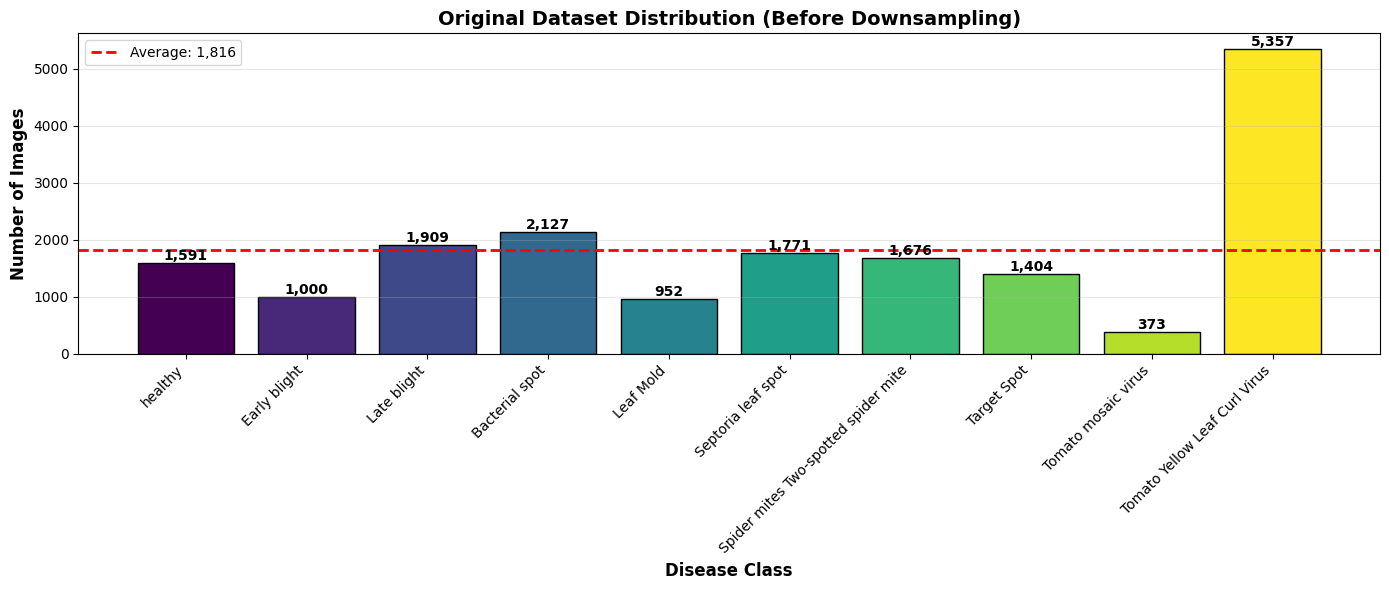


COMPARISON: BEFORE vs AFTER DOWNSAMPLING (target=1000)
Class                                    Original        After Downsample     Reduction      
healthy                                       1,591          1,000            37.1%
Early blight                                  1,000          1,000             0.0%
Late blight                                   1,909          1,000            47.6%
Bacterial spot                                2,127          1,000            53.0%
Leaf Mold                                       952            952             0.0%
Septoria leaf spot                            1,771          1,000            43.5%
Spider mites Two-spotted spider mite          1,676          1,000            40.3%
Target Spot                                   1,404          1,000            28.8%
Tomato mosaic virus                             373            373             0.0%
Tomato Yellow Leaf Curl Virus                 5,357          1,000            81.3%


In [4]:
# ============================================================================
# STEP 3: DEFINE CLASSES
# ============================================================================

print("\n" + "="*70)
print("STEP 3: DEFINING CLASSES")
print("="*70)

# Define the classes for Tomato Disease Detection
CLASSES = [
    'Tomato___healthy',
    'Tomato___Early_blight', 
    'Tomato___Late_blight',
    'Tomato___Bacterial_spot',
    'Tomato___Leaf_Mold',
    'Tomato___Septoria_leaf_spot',
    'Tomato___Spider_mites Two-spotted_spider_mite',
    'Tomato___Target_Spot',
    'Tomato___Tomato_mosaic_virus',
    'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
]

print(f"Classes defined: {len(CLASSES)}")
for i, cls in enumerate(CLASSES, 1):
    display_name = cls.replace('Tomato___', '').replace('_', ' ')
    print(f"  {i}. {display_name}")

# ============================================================================
# STEP 3A: ANALYZE ORIGINAL DATASET BEFORE DOWNSAMPLING
# ============================================================================

print("\n" + "="*70)
print("STEP 3A: ORIGINAL DATASET ANALYSIS (BEFORE DOWNSAMPLING)")
print("="*70)

def analyze_original_dataset(source_dir, classes_to_use):
    """
    Analyze the original dataset to see class distribution before downsampling
    
    Args:
        source_dir: Path to dataset (segmented folder)
        classes_to_use: List of class folder names to analyze
    """
    
    print(f"\nAnalyzing dataset from: {source_dir}")
    print(f"Classes to analyze: {len(classes_to_use)}\n")
    
    class_counts = {}
    
    # Count images in each class
    print("="*70)
    print(f"{'Class Name':<45} {'Image Count':<15}")
    print("="*70)
    
    for class_name in classes_to_use:
        source_class_dir = os.path.join(source_dir, class_name)
        
        if not os.path.exists(source_class_dir):
            print(f"{class_name:<45} NOT FOUND")
            class_counts[class_name] = 0
            continue
        
        # Count images
        images = [f for f in os.listdir(source_class_dir) 
                 if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        
        count = len(images)
        class_counts[class_name] = count
        
        # Clean name for display
        display_name = class_name.replace('Tomato___', '').replace('_', ' ')
        print(f"{display_name:<45} {count:>10,}")
    
    # Calculate statistics
    total_images = sum(class_counts.values())
    max_count = max(class_counts.values())
    min_count = min(class_counts.values())
    avg_count = total_images / len(classes_to_use) if classes_to_use else 0
    
    print("="*70)
    print(f"\n{'DATASET STATISTICS'}")
    print("="*70)
    print(f"Total Images:        {total_images:>10,}")
    print(f"Number of Classes:   {len(classes_to_use):>10,}")
    print(f"Average per Class:   {avg_count:>10,.0f}")
    print(f"Maximum Count:       {max_count:>10,}")
    print(f"Minimum Count:       {min_count:>10,}")
    print(f"Imbalance Ratio:     {max_count/min_count if min_count > 0 else 0:>10.2f}:1")
    
    # Visualize distribution
    plt.figure(figsize=(14, 6))
    
    # Clean class names for plotting
    clean_names = [name.replace('Tomato___', '').replace('_', ' ') for name in classes_to_use]
    counts = [class_counts[name] for name in classes_to_use]
    
    # Create bar plot
    colors = plt.cm.viridis(np.linspace(0, 1, len(classes_to_use)))
    bars = plt.bar(range(len(classes_to_use)), counts, color=colors, edgecolor='black')
    
    plt.xlabel('Disease Class', fontsize=12, fontweight='bold')
    plt.ylabel('Number of Images', fontsize=12, fontweight='bold')
    plt.title('Original Dataset Distribution (Before Downsampling)', fontsize=14, fontweight='bold')
    plt.xticks(range(len(classes_to_use)), clean_names, rotation=45, ha='right')
    plt.grid(axis='y', alpha=0.3)
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height):,}',
                ha='center', va='bottom', fontweight='bold')
    
    # Add horizontal line for average
    plt.axhline(y=avg_count, color='red', linestyle='--', linewidth=2, 
                label=f'Average: {avg_count:,.0f}')
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    return class_counts

# Analyze original dataset
print("\n" + "="*70)
print("ANALYZING ORIGINAL DATASET BEFORE DOWNSAMPLING")
print("="*70)
SOURCE_DIR = os.path.join(dataset_path, "segmented")
original_counts = analyze_original_dataset(SOURCE_DIR, CLASSES)

# Show what will happen after downsampling
print("\n" + "="*70)
print("COMPARISON: BEFORE vs AFTER DOWNSAMPLING (target=1000)")
print("="*70)
print(f"{'Class':<40} {'Original':<15} {'After Downsample':<20} {'Reduction':<15}")
print("="*70)

target_count = 1000
for class_name in CLASSES:
    original = original_counts.get(class_name, 0)
    after = min(original, target_count)
    reduction = ((original - after) / original * 100) if original > 0 else 0
    
    clean_name = class_name.replace('Tomato___', '').replace('_', ' ')
    print(f"{clean_name:<40} {original:>10,}     {after:>10,}          {reduction:>6.1f}%")

print("="*70)

In [5]:
# # ============================================================================
# # STEP 3: ORGANIZE DATASET INTO TRAIN/VAL/TEST SPLITS
# # ============================================================================

def organize_dataset_downsample(source_dir, output_dir, classes_to_use, target_count=700,train_ratio=0.7, val_ratio=0.15, test_ratio=0.15):
    """
    Downsample each class to target_count images and split into train/val/test.
    
    Args:
        source_dir: Path to dataset (segmented folder)
        output_dir: Where to save organized dataset
        classes_to_use: List of class folder names to use
        target_count: Number of images per class after downsampling
        train_ratio: Proportion for training (default 0.7)
        val_ratio: Proportion for validation (default 0.15)
        test_ratio: Proportion for testing (default 0.15)
    """
    
    # Create output directories
    splits = ['train', 'validation', 'test']
    for split in splits:
        for class_name in classes_to_use:
            Path(os.path.join(output_dir, split, class_name)).mkdir(parents=True, exist_ok=True)
    
    print(f"\nOrganizing dataset from: {source_dir}")
    print(f"Output directory: {output_dir}")
    print(f"Classes: {classes_to_use}")
    print(f"Target count per class: {target_count}")
    print(f"Split ratio - Train: {train_ratio}, Val: {val_ratio}, Test: {test_ratio}\n")
    
    # Process each class
    for class_name in classes_to_use:
        source_class_dir = os.path.join(source_dir, class_name)
        
        if not os.path.exists(source_class_dir):
            print(f"Warning: {source_class_dir} not found! Skipping...")
            continue
        
        # Get all images
        images = [f for f in os.listdir(source_class_dir) 
                 if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        
        # Shuffle images
        random.shuffle(images)
        
        # Downsample to target_count (or fewer if not enough images)
        selected = images[:target_count]
        total = len(selected)
        
        # Calculate split indices
        train_end = int(total * train_ratio)
        val_end = train_end + int(total * val_ratio)
        
        # Split images
        train_images = selected[:train_end]
        val_images = selected[train_end:val_end]
        test_images = selected[val_end:]
        
        # Copy files
        for split, split_images in [('train', train_images), 
                                     ('validation', val_images), 
                                     ('test', test_images)]:
            dest_dir = os.path.join(output_dir, split, class_name)
            
            for img in split_images:
                src = os.path.join(source_class_dir, img)
                dst = os.path.join(dest_dir, img)
                shutil.copy2(src, dst)
        
        print(f"{class_name:40s} - Train: {len(train_images):4d}, Val: {len(val_images):4d}, Test: {len(test_images):4d}, Total: {total:4d}")
    
    print("\n✓ Dataset organization with downsampling complete!")
    return output_dir

# Example usage:
SOURCE_DIR = os.path.join(dataset_path, "segmented")
OUTPUT_DIR = 'dataset'
CLASSES = [
    'Tomato___healthy',
    'Tomato___Early_blight', 
    'Tomato___Late_blight',
    # 'Tomato___Bacterial_spot',
    'Tomato___Septoria_leaf_spot',
    # 'Tomato___Spider_mites Two-spotted_spider_mite',
    'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
]

organize_dataset_downsample(SOURCE_DIR, OUTPUT_DIR, CLASSES, target_count=1000)



Organizing dataset from: /mnt/c/Users/Jimmy/anaconda_projects/cv project/plantvillage dataset/segmented
Output directory: dataset
Classes: ['Tomato___healthy', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus']
Target count per class: 1000
Split ratio - Train: 0.7, Val: 0.15, Test: 0.15

Tomato___healthy                         - Train:  700, Val:  150, Test:  150, Total: 1000
Tomato___Early_blight                    - Train:  700, Val:  150, Test:  150, Total: 1000
Tomato___Late_blight                     - Train:  700, Val:  150, Test:  150, Total: 1000
Tomato___Septoria_leaf_spot              - Train:  700, Val:  150, Test:  150, Total: 1000
Tomato___Tomato_Yellow_Leaf_Curl_Virus   - Train:  700, Val:  150, Test:  150, Total: 1000

✓ Dataset organization with downsampling complete!


'dataset'


STEP 4: DATASET EXPLORATION

DATASET STATISTICS

Training Set:
  Tomato___Early_blight                   :   700 images ( 20.0%)
  Tomato___Late_blight                    :   700 images ( 20.0%)
  Tomato___Septoria_leaf_spot             :   700 images ( 20.0%)
  Tomato___Tomato_Yellow_Leaf_Curl_Virus  :   700 images ( 20.0%)
  Tomato___healthy                        :   700 images ( 20.0%)
  Total                                   :  3500 images

Validation Set:
  Tomato___Early_blight                   :   150 images ( 20.0%)
  Tomato___Late_blight                    :   150 images ( 20.0%)
  Tomato___Septoria_leaf_spot             :   150 images ( 20.0%)
  Tomato___Tomato_Yellow_Leaf_Curl_Virus  :   150 images ( 20.0%)
  Tomato___healthy                        :   150 images ( 20.0%)
  Total                                   :   750 images

Test Set:
  Tomato___Early_blight                   :   150 images ( 20.0%)
  Tomato___Late_blight                    :   150 images ( 20.0%)
  

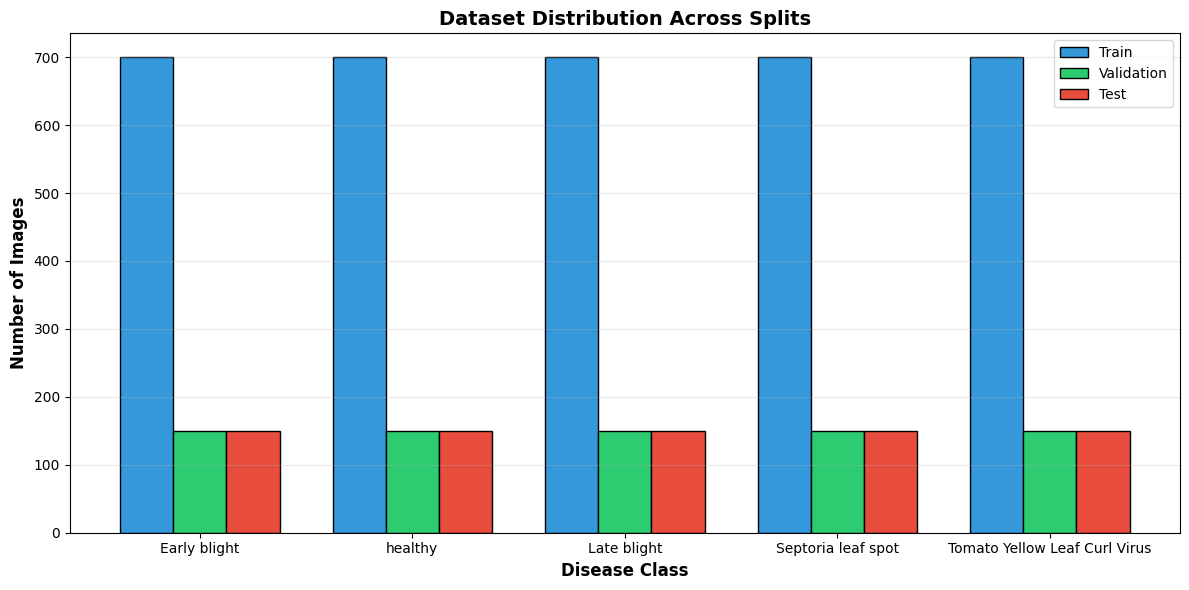

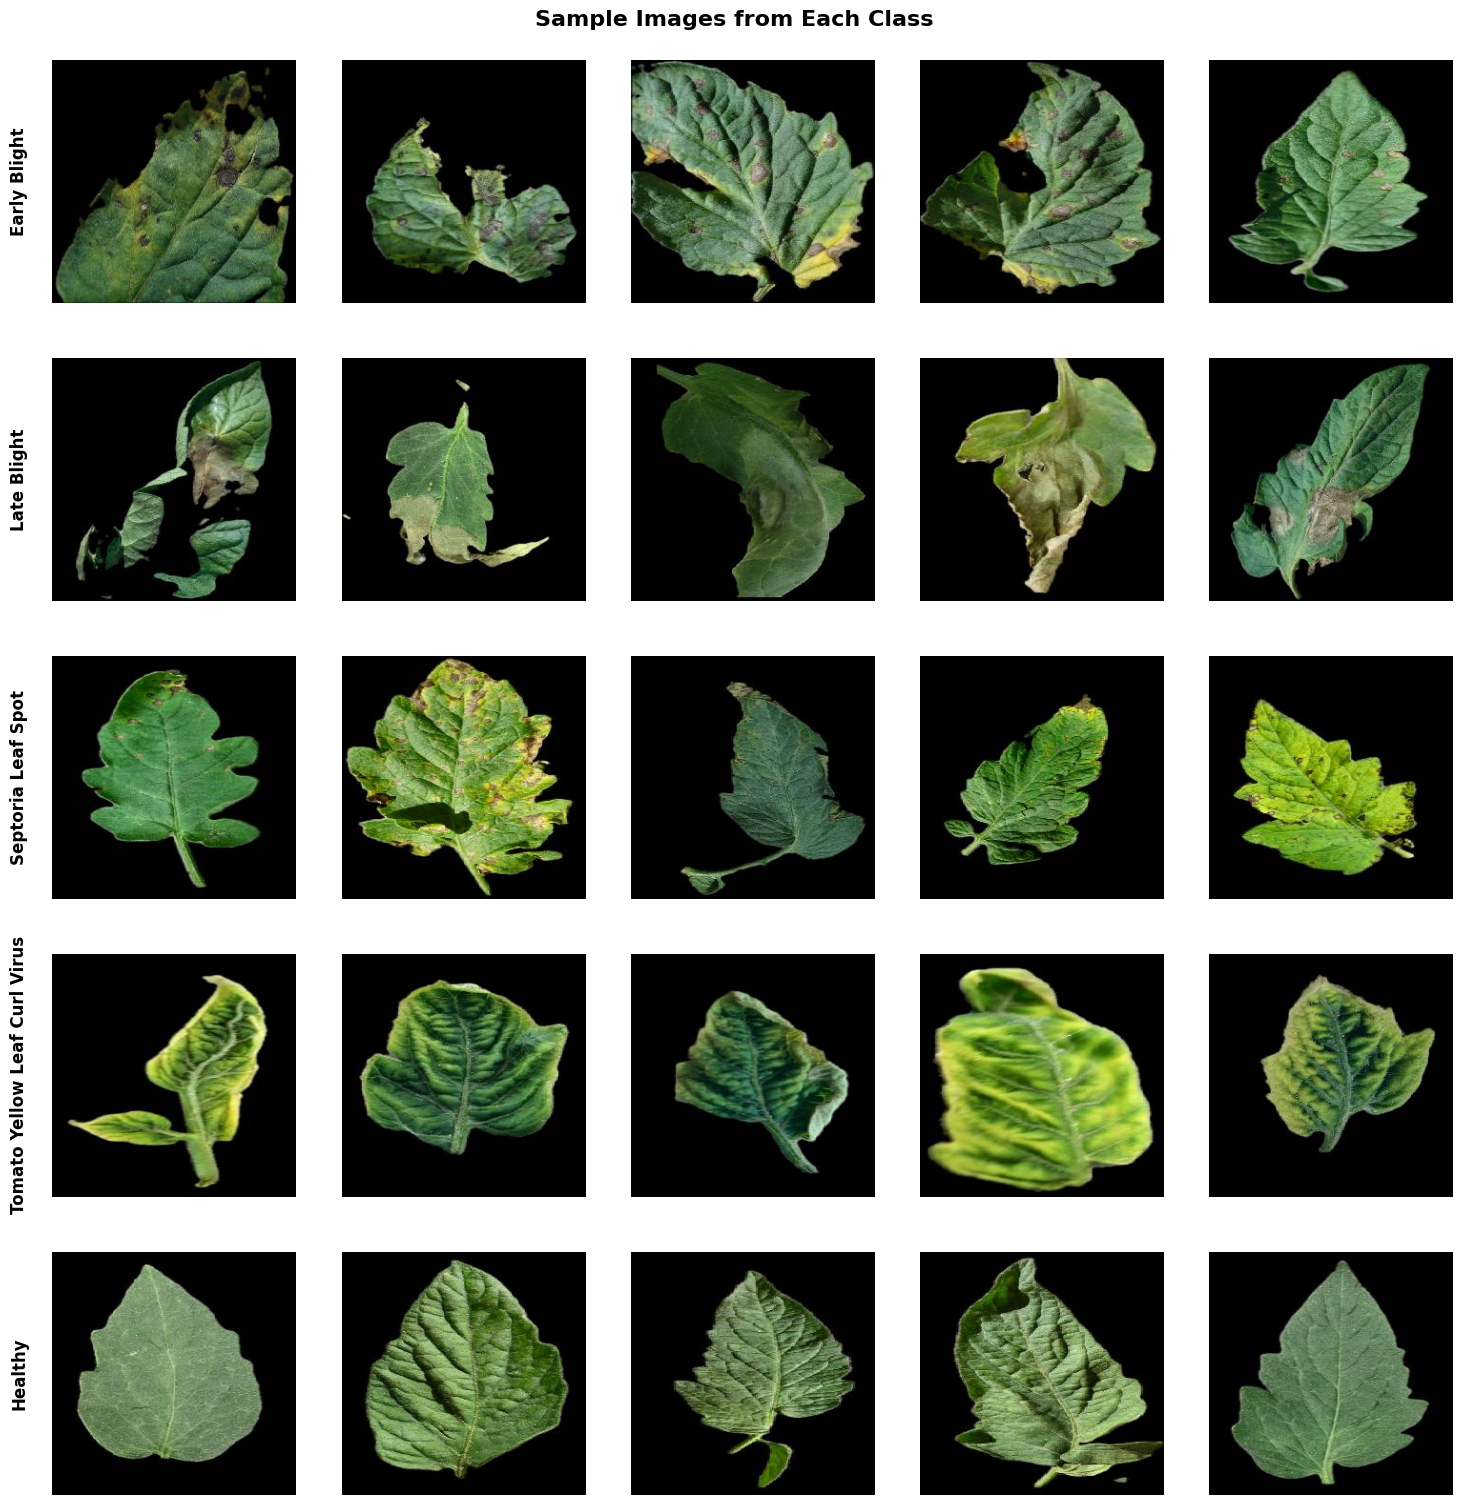

In [15]:
# ============================================================================
# STEP 4: VERIFY DATASET AND EXPLORE
# ============================================================================

print("\n" + "="*70)
print("STEP 4: DATASET EXPLORATION")
print("="*70)

# Set paths
BASE_DIR = 'dataset'
TRAIN_DIR = os.path.join(BASE_DIR, 'train')
VAL_DIR = os.path.join(BASE_DIR, 'validation')
TEST_DIR = os.path.join(BASE_DIR, 'test')

# Image parameters
IMG_SIZE = 224
BATCH_SIZE = 128
NUM_CLASSES = 5
# CLASS_NAMES = ['Tomato_Early_blight', 'Tomato_healthy', 'Tomato_Late_blight', 'Tomato_Bacterial_spot', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites Two-spotted_spider_mite', 'Tomato_Target_Spot', 'Tomato_Tomato_mosaic_virus', 'Tomato_Tomato_Yellow_Leaf_Curl_Virus']
CLASS_NAMES=['Tomato___healthy', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot',  'Tomato___Tomato_Yellow_Leaf_Curl_Virus']
def count_images(directory):
    """Count images in each class"""
    if not os.path.exists(directory):
        print(f"Directory {directory} does not exist!")
        return {}
    
    class_counts = {}
    for class_name in os.listdir(directory):
        class_path = os.path.join(directory, class_name)
        if os.path.isdir(class_path):
            count = len([f for f in os.listdir(class_path) 
                        if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
            class_counts[class_name] = count
    return class_counts

def display_dataset_info():
    """Display comprehensive dataset information"""
    print("\n" + "="*70)
    print("DATASET STATISTICS")
    print("="*70)
    
    for split_name, split_dir in [('Training', TRAIN_DIR), 
                                   ('Validation', VAL_DIR), 
                                   ('Test', TEST_DIR)]:
        counts = count_images(split_dir)
        if counts:
            total = sum(counts.values())
            print(f"\n{split_name} Set:")
            for class_name, count in sorted(counts.items()):
                percentage = (count / total * 100) if total > 0 else 0
                print(f"  {class_name:40s}: {count:5d} images ({percentage:5.1f}%)")
            print(f"  {'Total':40s}: {total:5d} images")
    
    # Check for class imbalance
    train_counts = count_images(TRAIN_DIR)
    if train_counts:
        max_count = max(train_counts.values())
        min_count = min(train_counts.values())
        imbalance_ratio = max_count / min_count if min_count > 0 else 0
        
        print(f"\n{'='*70}")
        print(f"Class Imbalance Ratio: {imbalance_ratio:.2f}:1")
        if imbalance_ratio > 3:
            print("⚠️  Warning: Significant class imbalance detected!")
        else:
            print("✓ Dataset is reasonably balanced")

# Run dataset info (uncomment when dataset is ready)
display_dataset_info()

def plot_class_distribution():
    """Visualize class distribution across splits"""
    splits = ['train', 'validation', 'test']
    data = []
    
    for split in splits:
        split_dir = os.path.join(BASE_DIR, split)
        counts = count_images(split_dir)
        for class_name, count in counts.items():
            # Clean class name for display
            clean_name = class_name.replace('Tomato___', '').replace('_', ' ')
            data.append({'Split': split.capitalize(), 'Class': clean_name, 'Count': count})
    
    df = pd.DataFrame(data)
    
    # Create grouped bar chart
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Get unique classes and splits
    classes = df['Class'].unique()
    x = np.arange(len(classes))
    width = 0.25
    
    colors = ['#3498db', '#2ecc71', '#e74c3c']
    
    for i, split in enumerate(['Train', 'Validation', 'Test']):
        split_data = df[df['Split'] == split]
        counts = [split_data[split_data['Class'] == c]['Count'].values[0] 
                 if len(split_data[split_data['Class'] == c]) > 0 else 0 
                 for c in classes]
        ax.bar(x + i*width, counts, width, label=split, color=colors[i], edgecolor='black')
    
    ax.set_xlabel('Disease Class', fontsize=12, fontweight='bold')
    ax.set_ylabel('Number of Images', fontsize=12, fontweight='bold')
    ax.set_title('Dataset Distribution Across Splits', fontsize=14, fontweight='bold')
    ax.set_xticks(x + width)
    ax.set_xticklabels(classes, rotation=0)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Plot distribution (uncomment when ready)
plot_class_distribution()

def show_sample_images():
    """Display sample images from each class"""
    if not os.path.exists(TRAIN_DIR):
        print("Training directory not found!")
        return
    
    classes = sorted([d for d in os.listdir(TRAIN_DIR) 
                     if os.path.isdir(os.path.join(TRAIN_DIR, d))])
    
    fig, axes = plt.subplots(len(classes), 5, figsize=(15, 3*len(classes)))
    fig.suptitle('Sample Images from Each Class', fontsize=16, fontweight='bold', y=1.00)
    
    for i, class_name in enumerate(classes):
        class_dir = os.path.join(TRAIN_DIR, class_name)
        images = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        
        # Clean name for display
        clean_name = class_name.replace('Tomato___', '').replace('_', ' ').title()
        
        for j in range(5):
            if j < len(images):
                img_path = os.path.join(class_dir, images[j])
                img = Image.open(img_path)
                
                if len(classes) > 1:
                    ax = axes[i, j]
                else:
                    ax = axes[j]
                
                ax.imshow(img)
                ax.axis('off')
                
                if j == 0:
                    ax.text(-0.1, 0.5, clean_name, transform=ax.transAxes,
                           fontsize=12, fontweight='bold', va='center', ha='right',
                           rotation=90)
    
    plt.tight_layout()
    plt.show()

# Show samples (uncomment when ready)
show_sample_images()



STEP 5: DATA PREPROCESSING & AUGMENTATION

Creating data generators...
Found 3500 images belonging to 5 classes.
Found 750 images belonging to 5 classes.
Found 750 images belonging to 5 classes.

✓ Data generators created successfully!
  Training samples: 3500
  Validation samples: 750
  Test samples: 750
  Class indices: {'Tomato___Early_blight': 0, 'Tomato___Late_blight': 1, 'Tomato___Septoria_leaf_spot': 2, 'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 3, 'Tomato___healthy': 4}
Found 3500 images belonging to 5 classes.
Found 3500 images belonging to 5 classes.


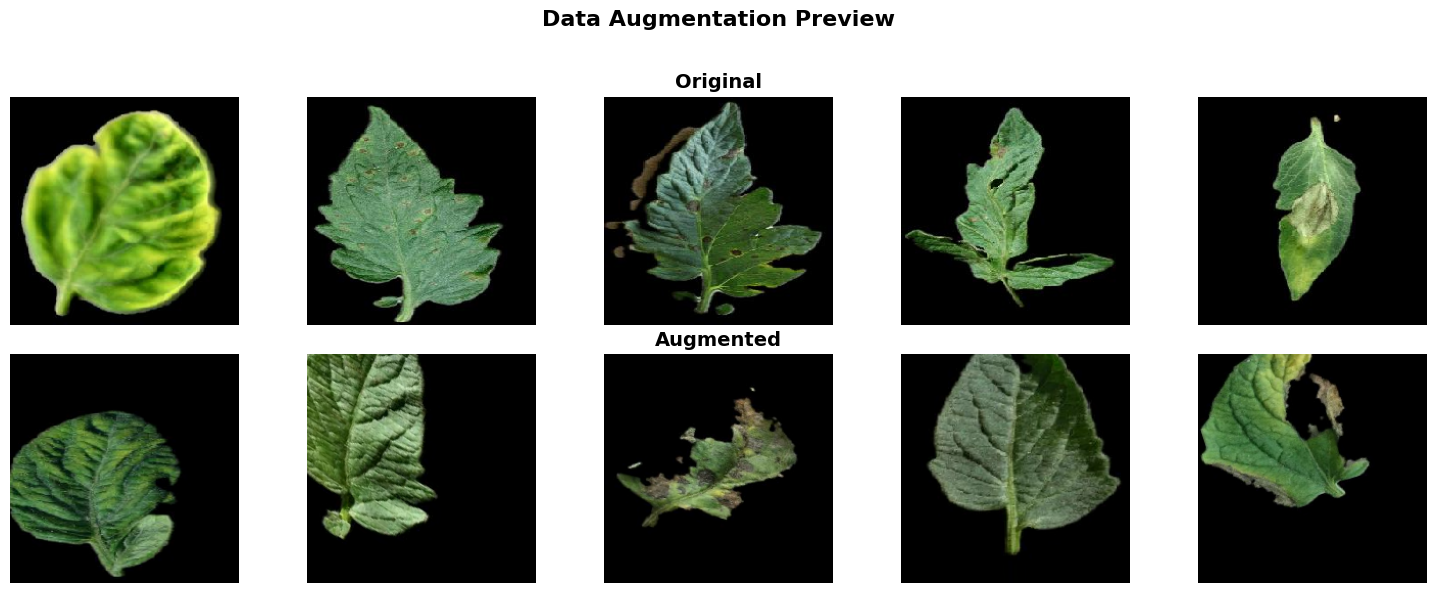

In [ ]:

# ============================================================================
# STEP 5: DATA PREPROCESSING AND AUGMENTATION
# ============================================================================

print("\n" + "="*70)
print("STEP 5: DATA PREPROCESSING & AUGMENTATION")
print("="*70)
#keras sequantial
# Training data augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=False,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# Validation and test (only rescaling)
val_test_datagen = ImageDataGenerator(rescale=1./255)

def create_generators():
    """Create data generators for train, validation, and test sets"""
    
    print("\nCreating data generators...")
    
    # Training generator
    train_generator = train_datagen.flow_from_directory(
        TRAIN_DIR,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=True,
        seed=42
    )
    
    # Validation generator
    val_generator = val_test_datagen.flow_from_directory(
        VAL_DIR,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=False
    )
    
    # Test generator
    test_generator = val_test_datagen.flow_from_directory(
        TEST_DIR,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=False
    )
    
    print(f"\n✓ Data generators created successfully!")
    print(f"  Training samples: {train_generator.samples}")
    print(f"  Validation samples: {val_generator.samples}")
    print(f"  Test samples: {test_generator.samples}")
    print(f"  Class indices: {train_generator.class_indices}")
    
    return train_generator, val_generator, test_generator

# Create generators (uncomment when dataset is ready)
train_gen, val_gen, test_gen = create_generators()

def visualize_augmentation(train_dir, datagen, num_images=5):
    """Visualize original vs augmented images with clear row labels"""

    # Generator without augmentation (only rescaling)
    plain_datagen = ImageDataGenerator(rescale=1./255)
    plain_gen = plain_datagen.flow_from_directory(
        train_dir,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=num_images,
        class_mode='categorical',
        shuffle=True
    )

    # Generator with augmentation
    aug_gen = datagen.flow_from_directory(
        train_dir,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=num_images,
        class_mode='categorical',
        shuffle=True
    )

    # Fetch one batch from each
    plain_images, _ = next(plain_gen)
    aug_images, _ = next(aug_gen)

    fig, axes = plt.subplots(2, num_images, figsize=(15, 6))
    fig.suptitle('Data Augmentation Preview', fontsize=16, fontweight='bold')

    # Top row: original images
    for i in range(num_images):
        axes[0, i].imshow(plain_images[i])
        axes[0, i].axis('off')
    # Add a row label as a title spanning the row
    axes[0, num_images//2].set_title('Original', fontsize=14, fontweight='bold')

    # Bottom row: augmented images
    for i in range(num_images):
        axes[1, i].imshow(aug_images[i])
        axes[1, i].axis('off')
    axes[1, num_images//2].set_title('Augmented', fontsize=14, fontweight='bold')

    plt.tight_layout(rect=[0, 0, 1, 0.95])  # leave space for the main title
    plt.show()



# Visualize augmentation (uncomment after creating generators)
visualize_augmentation(TRAIN_DIR, train_datagen, num_images=5)



In [8]:
# ============================================================================
# STEP 6: BUILD CUSTOM CNN MODEL
# ============================================================================

print("\n" + "="*70)
print("STEP 6: BUILDING CUSTOM CNN")
print("="*70)

def build_custom_cnn():
    """Build custom CNN from scratch"""
    
    model = models.Sequential(name='Custom_CNN')
    
    # Input layer
    model.add(layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
    
    # Block 1
    model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))
    
    # Block 2
    model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))
    
    # Block 3
    model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))
    
    # Block 4
    model.add(layers.Conv2D(256, (3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))
    
    # Fully connected layers
    model.add(layers.Flatten())
    model.add(layers.Dense(512, activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.5))
    
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.Dropout(0.5))
    
    # Output layer
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))
    
    return model

# Build custom CNN
custom_cnn = build_custom_cnn()

# Compile model
custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', 
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

print("\n✓ Custom CNN built successfully!")
print("\nModel Architecture:")
custom_cnn.summary()

print(f"\nTotal Parameters: {custom_cnn.count_params():,}")
trainable_params = sum([tf.size(w).numpy() for w in custom_cnn.trainable_weights])
print(f"Trainable Parameters: {trainable_params:,}")



STEP 6: BUILDING CUSTOM CNN


I0000 00:00:1768156292.246512  152478 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3537 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9



✓ Custom CNN built successfully!

Model Architecture:


Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 26,410,277 (100.75 MB)

 Trainable params: 26,407,845 (100.74 MB)

 Non-trainable params: 2,432 (9.50 KB)


Total Parameters: 26,410,277
Trainable Parameters: 26,407,845


In [9]:
# ============================================================================
# STEP 7: BUILD TRANSFER LEARNING MODEL
# ============================================================================

print("\n" + "="*70)
print("STEP 7: BUILDING TRANSFER LEARNING MODEL")
print("="*70)

def build_transfer_learning_model():
    """Build transfer learning model using EfficientNetB0"""
    
    # Load pre-trained base model
    base_model = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    
    # Freeze base model
    base_model.trainable = False
    
    # Build complete model
    model = models.Sequential(name='Transfer_Learning_EfficientNetB0')
    model.add(base_model)
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.5))
    
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.3))
    
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.3))
    
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))
    
    return model, base_model

# Build transfer learning model
transfer_model, base_model = build_transfer_learning_model()

# Compile model
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

print("\n✓ Transfer Learning model built successfully!")
print("\nModel Architecture:")
transfer_model.summary()

print(f"\nBase Model Layers: {len(base_model.layers)}")
print(f"Base Model Trainable: {base_model.trainable}")
print(f"Total Parameters: {transfer_model.count_params():,}")
trainable_params = sum([tf.size(w).numpy() for w in transfer_model.trainable_weights])
print(f"Trainable Parameters: {trainable_params:,}")



STEP 7: BUILDING TRANSFER LEARNING MODEL


2026-01-12 02:31:33.518294: E tensorflow/core/util/util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.



✓ Transfer Learning model built successfully!

Model Architecture:


Model: "Transfer_Learning_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,417,192 (16.85 MB)

 Trainable params: 364,549 (1.39 MB)

 Non-trainable params: 4,052,643 (15.46 MB)


Base Model Layers: 238
Base Model Trainable: False
Total Parameters: 4,417,192
Trainable Parameters: 364,549


In [10]:
# ============================================================================
# STEP 7: BUILD TRANSFER LEARNING MODEL EfficientNetB4
# ============================================================================
print("\n" + "="*70)
print("STEP 7: BUILDING TRANSFER LEARNING MODEL")
print("="*70)

def build_transfer_learning_model():
    """Build transfer learning model using EfficientNetB4"""
    
    # Load pre-trained base model
    base_model = EfficientNetB4(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    
    # Freeze base model
    base_model.trainable = False
    
    # Build complete model
    model = models.Sequential(name='Transfer_Learning_EfficientNetB4')
    model.add(base_model)
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.5))
    
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.3))
    
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.3))
    
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))
    
    return model, base_model

# Build transfer learning model
transfer_model_b4, base_model = build_transfer_learning_model()

# Compile model
transfer_model_b4.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

print("\n✓ Transfer Learning model built successfully!")
print("\nModel Architecture:")
transfer_model_b4.summary()

print(f"\nBase Model Layers: {len(base_model.layers)}")
print(f"Base Model Trainable: {base_model.trainable}")
print(f"Total Parameters: {transfer_model_b4.count_params():,}")
trainable_params = sum([tf.size(w).numpy() for w in transfer_model_b4.trainable_weights])
print(f"Trainable Parameters: {trainable_params:,}")



STEP 7: BUILDING TRANSFER LEARNING MODEL

✓ Transfer Learning model built successfully!

Model Architecture:


Model: "Transfer_Learning_EfficientNetB4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb4 (Functional)     │ (None, 7, 7, 1792)     │    17,673,823 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1792)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 1792)           │         7,168 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 1792)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       459,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,174,564 (69.33 MB)

 Trainable params: 496,645 (1.89 MB)

 Non-trainable params: 17,677,919 (67.44 MB)


Base Model Layers: 475
Base Model Trainable: False
Total Parameters: 18,174,564
Trainable Parameters: 496,645


In [4]:
# ============================================================================
# STEP 7: BUILD TRANSFER LEARNING MODEL (ResNet50)
# ============================================================================

print("\n" + "="*70)
print("STEP 7: BUILDING TRANSFER LEARNING MODEL (ResNet50)")
print("="*70)


def build_transfer_learning_model():
    """Build transfer learning model using ResNet50"""
    
    # Load pre-trained base model
    base_model = ResNet50(
        include_top=False,          # exclude original ImageNet classifier
        weights='imagenet',         # use pre-trained ImageNet weights
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    
    # Freeze base model
    base_model.trainable = False
    
    # Build complete model
    model = models.Sequential(name='Transfer_Learning_ResNet50')
    model.add(base_model)
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.5))
    
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.3))
    
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.3))
    
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))
    
    return model, base_model

# Build transfer learning model
resnet_model, base_model = build_transfer_learning_model()

# Compile model
resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

print("\n✓ Transfer Learning model (ResNet50) built successfully!")
print("\nModel Architecture:")
resnet_model.summary()

print(f"\nBase Model Layers: {len(base_model.layers)}")
print(f"Base Model Trainable: {base_model.trainable}")
print(f"Total Parameters: {resnet_model.count_params():,}")
trainable_params = sum([tf.size(w).numpy() for w in resnet_model.trainable_weights])
print(f"Trainable Parameters: {trainable_params:,}")



STEP 7: BUILDING TRANSFER LEARNING MODEL (ResNet50)


I0000 00:00:1768176947.761070     840 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3537 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9



✓ Transfer Learning model (ResNet50) built successfully!

Model Architecture:


Model: "Transfer_Learning_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,155,013 (92.14 MB)

 Trainable params: 562,693 (2.15 MB)

 Non-trainable params: 23,592,320 (90.00 MB)


Base Model Layers: 175
Base Model Trainable: False
Total Parameters: 24,155,013
Trainable Parameters: 562,693


In [17]:
# ============================================================================
# STEP 7: BUILD TRANSFER LEARNING MODEL (MobileNetV3Large)
# ============================================================================

print("\n" + "="*70)
print("STEP 7: BUILDING TRANSFER LEARNING MODEL (MobileNetV3Large)")
print("="*70)


def build_transfer_learning_model():
    """Build transfer learning model using MobileNetV3Large"""
    
    # Load pre-trained base model
    base_model = MobileNetV3Large(
        include_top=False,          # exclude original ImageNet classifier
        weights='imagenet',         # use pre-trained ImageNet weights
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    
    # Freeze base model
    base_model.trainable = False
    
    # Build complete model
    model = models.Sequential(name='Transfer_Learning_MobileNetV3Large')
    model.add(base_model)
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.5))
    
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.3))
    
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.3))
    
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))
    
    return model, base_model

# Build transfer learning model
mobilenet_model, base_model = build_transfer_learning_model()

# Compile model
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

print("\n✓ Transfer Learning model (MobileNetV3Large) built successfully!")
print("\nModel Architecture:")
mobilenet_model.summary()

print(f"\nBase Model Layers: {len(base_model.layers)}")
print(f"Base Model Trainable: {base_model.trainable}")
print(f"Total Parameters: {mobilenet_model.count_params():,}")
trainable_params = sum([tf.size(w).numpy() for w in mobilenet_model.trainable_weights])
print(f"Trainable Parameters: {trainable_params:,}")



STEP 7: BUILDING TRANSFER LEARNING MODEL (MobileNetV3Large)

✓ Transfer Learning model (MobileNetV3Large) built successfully!

Model Architecture:


Model: "Transfer_Learning_MobileNetV3Large"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Large (Functional)   │ (None, 7, 7, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 960)            │         3,840 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       246,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,280,773 (12.52 MB)

 Trainable params: 281,989 (1.08 MB)

 Non-trainable params: 2,998,784 (11.44 MB)


Base Model Layers: 187
Base Model Trainable: False
Total Parameters: 3,280,773
Trainable Parameters: 281,989


In [13]:

# ============================================================================
# STEP 8: TRAIN CUSTOM CNN
# ============================================================================

print("\n" + "="*70)
print("STEP 8: TRAINING CUSTOM CNN")
print("="*70)

# Create models directory
os.makedirs('models', exist_ok=True)

# Callbacks
custom_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=14,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=10,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        'models/custom_cnn_best.h5',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

EPOCHS = 100

print(f"\nTraining Configuration:")
print(f"  Epochs: {EPOCHS}")
print(f"  Batch Size: {BATCH_SIZE}")
print(f"  Image Size: {IMG_SIZE}x{IMG_SIZE}")
print(f"  Optimizer: Adam (lr=0.001)")
print(f"  Loss: Categorical Crossentropy")

# Train custom CNN (uncomment when generators are ready)
#
print("\n" + "="*70)
print("STARTING TRAINING - CUSTOM CNN")
print("="*70)

history_custom = custom_cnn.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=custom_callbacks,
    verbose=1
)

#Save final model
custom_cnn.save('models/custom_cnn_final.h5')
print("\n✓ Custom CNN training complete!")
print("  Model saved to: models/custom_cnn_final.h5")
#



STEP 8: TRAINING CUSTOM CNN

Training Configuration:
  Epochs: 100
  Batch Size: 32
  Image Size: 224x224
  Optimizer: Adam (lr=0.001)
  Loss: Categorical Crossentropy

STARTING TRAINING - CUSTOM CNN
Epoch 1/100


2026-01-12 02:31:42.806946: I external/local_xla/xla/service/service.cc:163] XLA service 0x76212c004fb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-01-12 02:31:42.806980: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9
2026-01-12 02:31:42.865253: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002
I0000 00:00:1768156303.109741  154031 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
2026-01-12 02:31:45.463285: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-01-12 02:31:46.970308: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Ma

 16/110 ━━━━━━━━━━━━━━━━━━━━ 52s 557ms/step - accuracy: 0.2424 - loss: 2.7777 - precision: 0.2344 - recall: 0.1754

2026-01-12 02:32:36.787411: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng0{} for conv (f16[32,3,3,32]{3,2,1,0}, u8[0]{0}) custom-call(f16[12,224,224,32]{3,2,1,0}, f16[12,224,224,32]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=b01f_o01i->b01f, custom_call_target="__cudnn$convBackwardFilter", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-01-12 02:32:37.391739: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.604540465s
Trying algorithm eng0{} for conv (f16[32,3,3,32]{3,2,1,0}, u8[0]{0}) custom-call(f16[12,224,224,32]{3,2,1,0}, f16[12,224,224,32]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=b01f_o01i->b01f, custom_call_target="__cudnn$convBackwardFilter", backend_config={"operation_

110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 635ms/step - accuracy: 0.3192 - loss: 2.1656 - precision: 0.3401 - recall: 0.2341
Epoch 1: val_accuracy improved from None to 0.25067, saving model to models/custom_cnn_best.h5


...

110/110 ━━━━━━━━━━━━━━━━━━━━ 65s 590ms/step - accuracy: 0.9329 - loss: 0.1873 - precision: 0.9369 - recall: 0.9289 - val_accuracy: 0.9013 - val_loss: 0.3668 - val_precision: 0.9081 - val_recall: 0.8960 - learning_rate: 5.0000e-04
Epoch 40/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step - accuracy: 0.9447 - loss: 0.1622 - precision: 0.9494 - recall: 0.9416
Epoch 40: val_accuracy improved from 0.90133 to 0.93733, saving model to models/custom_cnn_best.h5


110/110 ━━━━━━━━━━━━━━━━━━━━ 66s 595ms/step - accuracy: 0.9414 - loss: 0.1671 - precision: 0.9466 - recall: 0.9377 - val_accuracy: 0.9373 - val_loss: 0.2061 - val_precision: 0.9394 - val_recall: 0.9293 - learning_rate: 5.0000e-04
Epoch 41/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step - accuracy: 0.9386 - loss: 0.1994 - precision: 0.9427 - recall: 0.9332
Epoch 41: val_accuracy did not improve from 0.93733
110/110 ━━━━━━━━━━━━━━━━━━━━ 60s 541ms/step - accuracy: 0.9440 - loss: 0.1851 - precision: 0.9491 - recall: 0.9386 - val_accuracy: 0.6987 - val_loss: 1.1065 - val_precision: 0.7020 - val_recall: 0.6973 - learning_rate: 5.0000e-04
Epoch 42/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 473ms/step - accuracy: 0.9438 - loss: 0.1542 - precision: 0.9467 - recall: 0.9399
Epoch 42: val_accuracy did not improve from 0.93733
110/110 ━━━━━━━━━━━━━━━━━━━━ 60s 541ms/step - accuracy: 0.9394 - loss: 0.1727 - precision: 0.9422 - recall: 0.9357 - val_accuracy: 0.8693 - val_loss: 0.4110 - val_precision: 0.8745 -

110/110 ━━━━━━━━━━━━━━━━━━━━ 59s 537ms/step - accuracy: 0.9491 - loss: 0.1484 - precision: 0.9533 - recall: 0.9457 - val_accuracy: 0.9493 - val_loss: 0.1786 - val_precision: 0.9505 - val_recall: 0.9467 - learning_rate: 5.0000e-04
Epoch 49/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 459ms/step - accuracy: 0.9508 - loss: 0.1445 - precision: 0.9551 - recall: 0.9454
Epoch 49: val_accuracy did not improve from 0.94933
110/110 ━━━━━━━━━━━━━━━━━━━━ 58s 524ms/step - accuracy: 0.9511 - loss: 0.1467 - precision: 0.9550 - recall: 0.9469 - val_accuracy: 0.7027 - val_loss: 1.0903 - val_precision: 0.7032 - val_recall: 0.7013 - learning_rate: 5.0000e-04
Epoch 50/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 447ms/step - accuracy: 0.9519 - loss: 0.1464 - precision: 0.9549 - recall: 0.9487
Epoch 50: val_accuracy improved from 0.94933 to 0.96667, saving model to models/custom_cnn_best.h5


110/110 ━━━━━━━━━━━━━━━━━━━━ 62s 558ms/step - accuracy: 0.9477 - loss: 0.1559 - precision: 0.9516 - recall: 0.9431 - val_accuracy: 0.9667 - val_loss: 0.1052 - val_precision: 0.9678 - val_recall: 0.9627 - learning_rate: 5.0000e-04
Epoch 51/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.9463 - loss: 0.1586 - precision: 0.9512 - recall: 0.9406
Epoch 51: val_accuracy did not improve from 0.96667
110/110 ━━━━━━━━━━━━━━━━━━━━ 56s 507ms/step - accuracy: 0.9414 - loss: 0.1713 - precision: 0.9452 - recall: 0.9369 - val_accuracy: 0.7733 - val_loss: 0.7887 - val_precision: 0.7761 - val_recall: 0.7720 - learning_rate: 5.0000e-04
Epoch 52/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step - accuracy: 0.9475 - loss: 0.1522 - precision: 0.9505 - recall: 0.9438
Epoch 52: val_accuracy did not improve from 0.96667
110/110 ━━━━━━━━━━━━━━━━━━━━ 58s 525ms/step - accuracy: 0.9523 - loss: 0.1383 - precision: 0.9552 - recall: 0.9494 - val_accuracy: 0.8547 - val_loss: 0.3824 - val_precision: 0.8577 -


✓ Custom CNN training complete!
  Model saved to: models/custom_cnn_final.h5


In [8]:
# ============================================================================
# STEP 9: TRAIN TRANSFER LEARNING MODEL (ResNet50)
# ============================================================================

print("\n" + "="*70)
print("STEP 9: TRAINING TRANSFER LEARNING MODEL (ResNet50)")
print("="*70)

transfer_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=14,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=10,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        'models/transfer_learning_resnet50_best.h5',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

# -------------------------------
# PHASE 1: Training with frozen base model
# -------------------------------
print("\n" + "="*70)
print("PHASE 1: Training with frozen ResNet50 base model")
print("="*70)

# Ensure base model is frozen
base_model.trainable = False

history_resnet_phase1 = resnet_model.fit(
    train_gen,
    epochs=35,
    validation_data=val_gen,
    callbacks=transfer_callbacks,
    verbose=1
)

# -------------------------------
# PHASE 2: Fine-tuning - unfreezing top layers
# -------------------------------
print("\n" + "="*70)
print("PHASE 2: Fine-tuning - unfreezing top ResNet50 layers")
print("="*70)

# Unfreeze top layers
base_model.trainable = True

# Freeze all except last 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

print(f"Trainable layers: {sum([1 for layer in base_model.layers if layer.trainable])}")

# Recompile with lower learning rate for fine-tuning
resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

history_resnet_phase2 = resnet_model.fit(
    train_gen,
    epochs=50,
    validation_data=val_gen,
    callbacks=transfer_callbacks,
    verbose=1
)

# Save final model
resnet_model.save('models/transfer_learning_resnet50_final.h5')
print("\n✓ Transfer Learning training with ResNet50 complete!")
print("  Model saved to: models/transfer_learning_resnet50_final.h5")



STEP 9: TRAINING TRANSFER LEARNING MODEL (ResNet50)

PHASE 1: Training with frozen ResNet50 base model
Epoch 1/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step - accuracy: 0.5102 - loss: 1.2277 - precision: 0.6498 - recall: 0.3016
Epoch 1: val_accuracy improved from None to 0.62533, saving model to models/transfer_learning_resnet50_best.h5


110/110 ━━━━━━━━━━━━━━━━━━━━ 62s 564ms/step - accuracy: 0.4903 - loss: 1.2481 - precision: 0.6296 - recall: 0.2866 - val_accuracy: 0.6253 - val_loss: 0.9864 - val_precision: 0.7411 - val_recall: 0.4427 - learning_rate: 0.0010
Epoch 2/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 477ms/step - accuracy: 0.5036 - loss: 1.2118 - precision: 0.6571 - recall: 0.3111
Epoch 2: val_accuracy did not improve from 0.62533
110/110 ━━━━━━━━━━━━━━━━━━━━ 59s 539ms/step - accuracy: 0.5029 - loss: 1.2240 - precision: 0.6530 - recall: 0.3049 - val_accuracy: 0.5973 - val_loss: 1.0074 - val_precision: 0.7140 - val_recall: 0.4560 - learning_rate: 0.0010
Epoch 3/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step - accuracy: 0.5157 - loss: 1.1968 - precision: 0.6395 - recall: 0.3086
Epoch 3: val_accuracy did not improve from 0.62533
110/110 ━━━━━━━━━━━━━━━━━━━━ 60s 543ms/step - accuracy: 0.5126 - loss: 1.1973 - precision: 0.6513 - recall: 0.3117 - val_accuracy: 0.6053 - val_loss: 0.9662 - val_precision: 0.7329 - val_recall: 0

110/110 ━━━━━━━━━━━━━━━━━━━━ 60s 546ms/step - accuracy: 0.5140 - loss: 1.1812 - precision: 0.6685 - recall: 0.3054 - val_accuracy: 0.6333 - val_loss: 0.9343 - val_precision: 0.7647 - val_recall: 0.4507 - learning_rate: 0.0010
Epoch 10/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - accuracy: 0.5395 - loss: 1.1412 - precision: 0.6665 - recall: 0.3309
Epoch 10: val_accuracy did not improve from 0.63333
110/110 ━━━━━━━━━━━━━━━━━━━━ 60s 546ms/step - accuracy: 0.5337 - loss: 1.1589 - precision: 0.6669 - recall: 0.3334 - val_accuracy: 0.5960 - val_loss: 0.9888 - val_precision: 0.7035 - val_recall: 0.4493 - learning_rate: 0.0010
Epoch 11/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.5353 - loss: 1.1600 - precision: 0.7059 - recall: 0.3240
Epoch 11: val_accuracy did not improve from 0.63333
110/110 ━━━━━━━━━━━━━━━━━━━━ 60s 540ms/step - accuracy: 0.5323 - loss: 1.1604 - precision: 0.6890 - recall: 0.3291 - val_accuracy: 0.5987 - val_loss: 0.9928 - val_precision: 0.6925 - val_recal

110/110 ━━━━━━━━━━━━━━━━━━━━ 62s 565ms/step - accuracy: 0.5357 - loss: 1.1488 - precision: 0.6821 - recall: 0.3286 - val_accuracy: 0.6373 - val_loss: 0.9382 - val_precision: 0.7259 - val_recall: 0.4627 - learning_rate: 0.0010
Epoch 13/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 473ms/step - accuracy: 0.5430 - loss: 1.1517 - precision: 0.6687 - recall: 0.3454
Epoch 13: val_accuracy did not improve from 0.63733
110/110 ━━━━━━━━━━━━━━━━━━━━ 59s 535ms/step - accuracy: 0.5451 - loss: 1.1355 - precision: 0.6783 - recall: 0.3543 - val_accuracy: 0.6293 - val_loss: 0.9211 - val_precision: 0.7561 - val_recall: 0.4960 - learning_rate: 0.0010
Epoch 14/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.5339 - loss: 1.1629 - precision: 0.6884 - recall: 0.3484
Epoch 14: val_accuracy did not improve from 0.63733
110/110 ━━━━━━━━━━━━━━━━━━━━ 60s 542ms/step - accuracy: 0.5391 - loss: 1.1482 - precision: 0.6926 - recall: 0.3509 - val_accuracy: 0.6240 - val_loss: 0.9360 - val_precision: 0.7241 - val_recal

110/110 ━━━━━━━━━━━━━━━━━━━━ 62s 564ms/step - accuracy: 0.5260 - loss: 1.1511 - precision: 0.6791 - recall: 0.3434 - val_accuracy: 0.6520 - val_loss: 0.8982 - val_precision: 0.7829 - val_recall: 0.4760 - learning_rate: 0.0010
Epoch 16/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 442ms/step - accuracy: 0.5494 - loss: 1.1186 - precision: 0.7188 - recall: 0.3508
Epoch 16: val_accuracy did not improve from 0.65200
110/110 ━━━━━━━━━━━━━━━━━━━━ 55s 501ms/step - accuracy: 0.5380 - loss: 1.1344 - precision: 0.7114 - recall: 0.3451 - val_accuracy: 0.6307 - val_loss: 0.9253 - val_precision: 0.7389 - val_recall: 0.4680 - learning_rate: 0.0010
Epoch 17/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step - accuracy: 0.5452 - loss: 1.1327 - precision: 0.6922 - recall: 0.3488
Epoch 17: val_accuracy did not improve from 0.65200
110/110 ━━━━━━━━━━━━━━━━━━━━ 58s 529ms/step - accuracy: 0.5434 - loss: 1.1309 - precision: 0.6887 - recall: 0.3514 - val_accuracy: 0.6400 - val_loss: 0.8915 - val_precision: 0.7860 - val_recal

110/110 ━━━━━━━━━━━━━━━━━━━━ 60s 544ms/step - accuracy: 0.5551 - loss: 1.1143 - precision: 0.6864 - recall: 0.3714 - val_accuracy: 0.6533 - val_loss: 0.8521 - val_precision: 0.7908 - val_recall: 0.5040 - learning_rate: 0.0010
Epoch 28/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step - accuracy: 0.5651 - loss: 1.1067 - precision: 0.7024 - recall: 0.3588
Epoch 28: val_accuracy did not improve from 0.65333
110/110 ━━━━━━━━━━━━━━━━━━━━ 56s 510ms/step - accuracy: 0.5571 - loss: 1.1129 - precision: 0.7050 - recall: 0.3611 - val_accuracy: 0.6427 - val_loss: 0.8531 - val_precision: 0.7771 - val_recall: 0.5253 - learning_rate: 0.0010
Epoch 29/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 445ms/step - accuracy: 0.5571 - loss: 1.1077 - precision: 0.6951 - recall: 0.3713
Epoch 29: val_accuracy did not improve from 0.65333
110/110 ━━━━━━━━━━━━━━━━━━━━ 84s 506ms/step - accuracy: 0.5557 - loss: 1.1083 - precision: 0.6972 - recall: 0.3697 - val_accuracy: 0.6120 - val_loss: 0.9635 - val_precision: 0.6956 - val_recal

110/110 ━━━━━━━━━━━━━━━━━━━━ 59s 539ms/step - accuracy: 0.5540 - loss: 1.1243 - precision: 0.7002 - recall: 0.3557 - val_accuracy: 0.6547 - val_loss: 0.8665 - val_precision: 0.7670 - val_recall: 0.4960 - learning_rate: 0.0010
Epoch 32/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step - accuracy: 0.5475 - loss: 1.1193 - precision: 0.6785 - recall: 0.3599
Epoch 32: val_accuracy did not improve from 0.65467
110/110 ━━━━━━━━━━━━━━━━━━━━ 56s 510ms/step - accuracy: 0.5526 - loss: 1.1117 - precision: 0.6874 - recall: 0.3637 - val_accuracy: 0.6480 - val_loss: 0.8824 - val_precision: 0.7624 - val_recall: 0.5133 - learning_rate: 0.0010
Epoch 33/35
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 442ms/step - accuracy: 0.5532 - loss: 1.1107 - precision: 0.7071 - recall: 0.3693
Epoch 33: val_accuracy did not improve from 0.65467
110/110 ━━━━━━━━━━━━━━━━━━━━ 55s 498ms/step - accuracy: 0.5580 - loss: 1.1083 - precision: 0.7003 - recall: 0.3686 - val_accuracy: 0.6453 - val_loss: 0.8842 - val_precision: 0.7500 - val_recal

110/110 ━━━━━━━━━━━━━━━━━━━━ 54s 490ms/step - accuracy: 0.5551 - loss: 1.1019 - precision: 0.7121 - recall: 0.3689 - val_accuracy: 0.6800 - val_loss: 0.8299 - val_precision: 0.8037 - val_recall: 0.5187 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 35.

PHASE 2: Fine-tuning - unfreezing top ResNet50 layers
Trainable layers: 20
Epoch 1/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step - accuracy: 0.5645 - loss: 1.0827 - precision: 0.7122 - recall: 0.3765
Epoch 1: val_accuracy did not improve from 0.68000
110/110 ━━━━━━━━━━━━━━━━━━━━ 86s 587ms/step - accuracy: 0.5623 - loss: 1.0934 - precision: 0.7188 - recall: 0.3806 - val_accuracy: 0.6667 - val_loss: 0.8438 - val_precision: 0.7867 - val_recall: 0.5213 - learning_rate: 1.0000e-04
Epoch 2/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 438ms/step - accuracy: 0.5526 - loss: 1.1190 - precision: 0.6779 - recall: 0.3700
Epoch 2: val_accuracy did not improve from 0.68000
110/110 ━━━━━━━━━━━━━━━━━━━━ 54s 493ms/step - accuracy: 


✓ Transfer Learning training with ResNet50 complete!
  Model saved to: models/transfer_learning_resnet50_final.h5


In [19]:
# ============================================================================
# STEP 9: TRAIN TRANSFER LEARNING MODEL (MobileNetV3Large)
# ============================================================================

print("\n" + "="*70)
print("STEP 9: TRAINING TRANSFER LEARNING MODEL (MobileNetV3Large)")
print("="*70)

transfer_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=14,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=10,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        'models/transfer_learning_mobilenetv3_best.h5',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

# -------------------------------
# PHASE 1: Training with frozen base model
# -------------------------------
print("\n" + "="*70)
print("PHASE 1: Training with frozen MobileNetV3 base model")
print("="*70)

# Ensure base model is frozen
base_model.trainable = False

history_mobilenet_phase1 = mobilenet_model.fit(
    train_gen,
    epochs=35,
    validation_data=val_gen,
    callbacks=transfer_callbacks,
    verbose=1
)

# -------------------------------
# PHASE 2: Fine-tuning - unfreezing top layers
# -------------------------------
print("\n" + "="*70)
print("PHASE 2: Fine-tuning - unfreezing top MobileNetV3 layers")
print("="*70)

# Unfreeze top layers
base_model.trainable = True

# Freeze all except last 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

print(f"Trainable layers: {sum([1 for layer in base_model.layers if layer.trainable])}")

# Recompile with lower learning rate for fine-tuning
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

history_mobilenet_phase2 = mobilenet_model.fit(
    train_gen,
    epochs=50,
    validation_data=val_gen,
    callbacks=transfer_callbacks,
    verbose=1
)

# Save final model
mobilenet_model.save('models/transfer_learning_mobilenetv3_final.h5')
print("\n✓ Transfer Learning training with MobileNetV3 complete!")
print("  Model saved to: models/transfer_learning_mobilenetv3_final.h5")



STEP 9: TRAINING TRANSFER LEARNING MODEL (MobileNetV3Large)

PHASE 1: Training with frozen MobileNetV3 base model
Epoch 1/35
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2227 - loss: 2.2791 - precision: 0.2264 - recall: 0.1199

2026-01-12 11:17:20.167606: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1830', 304 bytes spill stores, 304 bytes spill loads

2026-01-12 11:17:28.920874: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1830', 304 bytes spill stores, 304 bytes spill loads




Epoch 1: val_accuracy improved from None to 0.20267, saving model to models/transfer_learning_mobilenetv3_best.h5


28/28 ━━━━━━━━━━━━━━━━━━━━ 86s 3s/step - accuracy: 0.2569 - loss: 2.0942 - precision: 0.2856 - recall: 0.1494 - val_accuracy: 0.2027 - val_loss: 1.6281 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/35
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3129 - loss: 1.7306 - precision: 0.3849 - recall: 0.1704
Epoch 2: val_accuracy improved from 0.20267 to 0.22533, saving model to models/transfer_learning_mobilenetv3_best.h5


28/28 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.3123 - loss: 1.7126 - precision: 0.4008 - recall: 0.1749 - val_accuracy: 0.2253 - val_loss: 1.5933 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/35
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3272 - loss: 1.6476 - precision: 0.4314 - recall: 0.1718
Epoch 3: val_accuracy improved from 0.22533 to 0.24000, saving model to models/transfer_learning_mobilenetv3_best.h5


...


Epoch 33: val_accuracy did not improve from 0.57467
28/28 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.4669 - loss: 1.2768 - precision: 0.6453 - recall: 0.2126 - val_accuracy: 0.5480 - val_loss: 1.0705 - val_precision: 0.8159 - val_recall: 0.3013 - learning_rate: 0.0010
Epoch 34/35
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4964 - loss: 1.2405 - precision: 0.6862 - recall: 0.2087
Epoch 34: val_accuracy improved from 0.57467 to 0.58133, saving model to models/transfer_learning_mobilenetv3_best.h5


28/28 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.4751 - loss: 1.2609 - precision: 0.6645 - recall: 0.2071 - val_accuracy: 0.5813 - val_loss: 1.0562 - val_precision: 0.8364 - val_recall: 0.3000 - learning_rate: 0.0010
Epoch 35/35
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4834 - loss: 1.2501 - precision: 0.6839 - recall: 0.2284
Epoch 35: val_accuracy did not improve from 0.58133
28/28 ━━━━━━━━━━━━━━━━━━━━ 55s 2s/step - accuracy: 0.4711 - loss: 1.2608 - precision: 0.6736 - recall: 0.2211 - val_accuracy: 0.5627 - val_loss: 1.0412 - val_precision: 0.8095 - val_recall: 0.3400 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 35.

PHASE 2: Fine-tuning - unfreezing top MobileNetV3 layers
Trainable layers: 20
Epoch 1/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.1977 - loss: 2.0757 - precision: 0.1804 - recall: 0.0450
Epoch 1: val_accuracy did not improve from 0.58133
28/28 ━━━━━━━━━━━━━━━━━━━━ 94s 3s/step - accuracy: 0.2257 - loss: 1.9248 - 

2026-01-12 11:54:13.621955: W tensorflow/core/kernels/data/prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 77072896 bytes after encountering the first element of size 77072896 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3957 - loss: 1.4047 - precision: 0.6355 - recall: 0.1379
Epoch 5: val_accuracy did not improve from 0.58133
28/28 ━━━━━━━━━━━━━━━━━━━━ 53s 2s/step - accuracy: 0.4057 - loss: 1.3917 - precision: 0.6361 - recall: 0.1429 - val_accuracy: 0.2133 - val_loss: 1.6719 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 6/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4265 - loss: 1.3485 - precision: 0.6670 - recall: 0.1667
Epoch 6: val_accuracy did not improve from 0.58133
28/28 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.4294 - loss: 1.3522 - precision: 0.6477 - recall: 0.1654 - val_accuracy: 0.2133 - val_loss: 1.7065 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 7/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4533 - loss: 1.3239 - precision: 0.6846 - recall: 0.1829
Epoch 7: val_accuracy did not improve from 0.58133
28/28 ━━━━━━━━━━━━━━━━━━━━ 51s 2


✓ Transfer Learning training with MobileNetV3 complete!
  Model saved to: models/transfer_learning_mobilenetv3_final.h5


In [13]:

# ============================================================================
# STEP 10: VISUALIZE TRAINING HISTORY
# ============================================================================

def plot_training_history(history, model_name='Model'):
    """Plot training curves"""
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle(f'{model_name} - Training History', fontsize=16, fontweight='bold')
    
    # Accuracy
    axes[0, 0].plot(history.history['accuracy'], label='Train', linewidth=2, marker='o')
    axes[0, 0].plot(history.history['val_accuracy'], label='Validation', linewidth=2, marker='s')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Accuracy')
    axes[0, 0].set_title('Model Accuracy')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Loss
    axes[0, 1].plot(history.history['loss'], label='Train', linewidth=2, marker='o')
    axes[0, 1].plot(history.history['val_loss'], label='Validation', linewidth=2, marker='s')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].set_title('Model Loss')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Precision
    if 'precision' in history.history:
        axes[1, 0].plot(history.history['precision'], label='Train', linewidth=2, marker='o')
        axes[1, 0].plot(history.history['val_precision'], label='Validation', linewidth=2, marker='s')
        axes[1, 0].set_xlabel('Epoch')
        axes[1, 0].set_ylabel('Precision')
        axes[1, 0].set_title('Model Precision')
        axes[1, 0].legend()
        axes[1, 0].grid(True, alpha=0.3)
    
    # Recall
    if 'recall' in history.history:
        axes[1, 1].plot(history.history['recall'], label='Train', linewidth=2, marker='o')
        axes[1, 1].plot(history.history['val_recall'], label='Validation', linewidth=2, marker='s')
        axes[1, 1].set_xlabel('Epoch')
        axes[1, 1].set_ylabel('Recall')
        axes[1, 1].set_title('Model Recall')
        axes[1, 1].legend()
        axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# ============================================================================
# Plot histories for all models
# ============================================================================

# Custom CNN
plot_training_history(history_custom, 'Custom CNN')

# ResNet50 Transfer Learning
plot_training_history(history_resnet_phase2, 'Transfer Learning (ResNet50)')

# MobileNetV3Large Transfer Learning
plot_training_history(history_mobilenet_phase2, 'Transfer Learning (MobileNetV3Large)')


NameError: name 'history_custom' is not defined

In [ ]:

# ============================================================================
# STEP 11: EVALUATE MODELS
# ============================================================================

print("\n" + "="*70)
print("STEP 11: MODEL EVALUATION")
print("="*70)

def evaluate_model(model, test_generator, model_name='Model'):
    """Comprehensive model evaluation"""
    
    print(f"\n{'='*70}")
    print(f"EVALUATING: {model_name}")
    print(f"{'='*70}")
    
    # Reset generator
    test_generator.reset()
    
    # Get predictions
    print("\nGenerating predictions...")
    predictions = model.predict(test_generator, verbose=1)
    y_pred = np.argmax(predictions, axis=1)
    y_true = test_generator.classes
    
    # Get class names
    class_names = list(test_generator.class_indices.keys())
    class_names = [name.replace('Tomato___', '').replace('_', ' ') for name in class_names]
    
    # Calculate metrics
    accuracy = accuracy_score(y_true, y_pred)
    
    print(f"\n{'='*70}")
    print(f"OVERALL ACCURACY: {accuracy*100:.2f}%")
    print(f"{'='*70}")
    
    # Classification report
    print("\nDetailed Classification Report:")
    print("="*70)
    report = classification_report(y_true, y_pred, target_names=class_names, digits=4)
    print(report)
    
    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # Plot confusion matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Count'}, annot_kws={'size': 14})
    plt.title(f'{model_name} - Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
    plt.ylabel('True Label', fontsize=12, fontweight='bold')
    plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Per-class metrics
    print("\nPer-Class Performance:")
    print("="*70)
    print(f"{'Class':<30} {'Accuracy':<12} {'Precision':<12} {'Recall':<12} {'F1-Score':<12}")
    print("="*70)
    
    for i, class_name in enumerate(class_names):
        class_acc = cm[i, i] / cm[i].sum() * 100 if cm[i].sum() > 0 else 0
        
        # Calculate precision, recall, f1
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        
        print(f"{class_name:<30} {class_acc:>6.2f}%      {precision:>6.4f}       {recall:>6.4f}       {f1:>6.4f}")
    
    return y_pred, y_true, accuracy, predictions


# ============================================================================
# Evaluate models (uncomment after training)
# ============================================================================

Evaluate Custom CNN
custom_pred, custom_true, custom_acc, custom_predictions = evaluate_model(
    custom_cnn, test_gen, 'Custom CNN'
)

# Evaluate Transfer Learning - ResNet50
resnet_pred, resnet_true, resnet_acc, resnet_predictions = evaluate_model(
    resnet_model, test_gen, 'Transfer Learning - ResNet50'
)

# Evaluate Transfer Learning - MobileNetV3Large
mobilenet_pred, mobilenet_true, mobilenet_acc, mobilenet_predictions = evaluate_model(
    mobilenet_model, test_gen, 'Transfer Learning - MobileNetV3Large'
)

# ============================================================================
# Compare models
# ============================================================================

print("\n" + "="*70)
print("MODEL COMPARISON SUMMARY")
print("="*70)
print(f"{'Model':<40} {'Accuracy':<15} {'Parameters':<15}")
print("="*70)
print(f"{'Custom CNN':<40} {custom_acc*100:>6.2f}%        {custom_cnn.count_params():>12,}")
print(f"{'Transfer Learning (ResNet50)':<40} {resnet_acc*100:>6.2f}%        {resnet_model.count_params():>12,}")
print(f"{'Transfer Learning (MobileNetV3Large)':<40} {mobilenet_acc*100:>6.2f}%        {mobilenet_model.count_params():>12,}")
print("="*70)


# Highlight best performer
best_model = max(
    [('Custom CNN', custom_acc), 
     ('ResNet50', resnet_acc), 
     ('MobileNetV3Large', mobilenet_acc)],
    key=lambda x: x[1]
)

print(f"\n✓ Best performing model: {best_model[0]} with accuracy {best_model[1]*100:.2f}%")


In [ ]:

# ============================================================================
# STEP 12: VISUALIZE PREDICTIONS
# ============================================================================

def visualize_predictions(model, test_generator, num_images=12, model_name="Model"):
    """Visualize model predictions"""
    
    # Get predictions
    test_generator.reset()
    images, labels = next(test_generator)
    predictions = model.predict(images, verbose=0)
    
    class_names = list(test_generator.class_indices.keys())
    class_names = [name.replace('Tomato___', '').replace('_', ' ') for name in class_names]
    
    # Create grid
    rows = 3
    cols = 4
    fig, axes = plt.subplots(rows, cols, figsize=(16, 12))
    axes = axes.flatten()
    fig.suptitle(f'{model_name} - Predictions on Test Set', fontsize=16, fontweight='bold')
    
    for i in range(min(num_images, len(images))):
        ax = axes[i]
        
        # Display image
        ax.imshow(images[i])
        
        # Get prediction
        pred_idx = np.argmax(predictions[i])
        true_idx = np.argmax(labels[i])
        confidence = predictions[i][pred_idx] * 100
        
        pred_name = class_names[pred_idx]
        true_name = class_names[true_idx]
        
        # Color code: green if correct, red if wrong
        color = 'green' if pred_idx == true_idx else 'red'
        
        title = f"True: {true_name}\nPred: {pred_name}\nConf: {confidence:.1f}%"
        ax.set_title(title, fontsize=10, fontweight='bold', color=color)
        ax.axis('off')
    
    # Hide extra subplots
    for i in range(num_images, len(axes)):
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.show()


# ============================================================================
# Visualize predictions for all models (uncomment after training)
# ============================================================================

# Custom CNN
visualize_predictions(custom_cnn, test_gen, num_images=12, model_name="Custom CNN")

# ResNet50 Transfer Learning
visualize_predictions(resnet_model, test_gen, num_images=12, model_name="Transfer Learning (ResNet50)")

# MobileNetV3Large Transfer Learning
visualize_predictions(mobilenet_model, test_gen, num_images=12, model_name="Transfer Learning (MobileNetV3Large)")

In [ ]:

# ============================================================================
# STEP 13: ERROR ANALYSIS
# ============================================================================

def error_analysis(model, test_generator, num_errors=9, model_name="Model"):
    """Analyze misclassified images"""
    
    # Get all predictions
    test_generator.reset()
    predictions = model.predict(test_generator, verbose=0)
    y_pred = np.argmax(predictions, axis=1)
    y_true = test_generator.classes
    
    # Find misclassified
    misclassified_idx = np.where(y_pred != y_true)[0]
    
    print(f"\n{'='*70}")
    print(f"ERROR ANALYSIS - {model_name}")
    print(f"{'='*70}")
    print(f"Total Test Samples: {len(y_true)}")
    print(f"Misclassified: {len(misclassified_idx)}")
    print(f"Error Rate: {len(misclassified_idx)/len(y_true)*100:.2f}%")
    
    if len(misclassified_idx) == 0:
        print("\n🎉 Perfect predictions! No errors found!")
        return
    
    class_names = list(test_generator.class_indices.keys())
    class_names = [name.replace('Tomato___', '').replace('_', ' ') for name in class_names]
    
    # Analyze error patterns
    print(f"\nMisclassification Patterns:")
    print("="*70)
    print(f"{'True Label':<25} {'→':<5} {'Predicted As':<25} {'Count':<10}")
    print("="*70)
    
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            if i != j:
                count = np.sum((y_true == i) & (y_pred == j))
                if count > 0:
                    print(f"{class_names[i]:<25} {'→':<5} {class_names[j]:<25} {count:<10}")
    
    # Visualize errors
    if len(misclassified_idx) > 0:
        fig, axes = plt.subplots(3, 3, figsize=(15, 15))
        axes = axes.flatten()
        fig.suptitle(f'Misclassified Examples - {model_name}', fontsize=16, fontweight='bold', color='red')
        
        for i, idx in enumerate(misclassified_idx[:num_errors]):
            # Get image
            batch_idx = idx // test_generator.batch_size
            img_idx = idx % test_generator.batch_size
            
            test_generator.reset()
            for _ in range(batch_idx + 1):
                images, labels = next(test_generator)
            
            img = images[img_idx]
            true_label = class_names[y_true[idx]]
            pred_label = class_names[y_pred[idx]]
            confidence = predictions[idx][y_pred[idx]] * 100
            
            axes[i].imshow(img)
            axes[i].set_title(f"True: {true_label}\nPredicted: {pred_label}\nConfidence: {confidence:.1f}%",
                            fontsize=10, fontweight='bold', color='red')
            axes[i].axis('off')
        
        # Hide extra subplots
        for i in range(len(misclassified_idx[:num_errors]), len(axes)):
            axes[i].axis('off')
        
        plt.tight_layout()
        plt.show()


# ============================================================================
# Run error analysis for all models (uncomment after training)
# ============================================================================

# Custom CNN
error_analysis(custom_cnn, test_gen, num_errors=9, model_name="Custom CNN")

# ResNet50 Transfer Learning
error_analysis(resnet_model, test_gen, num_errors=9, model_name="Transfer Learning (ResNet50)")

# MobileNetV3Large Transfer Learning
error_analysis(mobilenet_model, test_gen, num_errors=9, model_name="Transfer Learning (MobileNetV3Large)")


In [ ]:

# ============================================================================
# STEP 14: SIMPLE DEMO - PREDICT SINGLE IMAGE
# ============================================================================

def predict_single_image(model, image_path, class_names=None):
    """
    Predict disease for a single image
    
    Args:
        model: Trained model
        image_path: Path to image file
        class_names: List of class names
    
    Returns:
        predicted_class, confidence
    """
    
    if class_names is None:
        class_names = ['Early Blight', 'Late Blight', 'Healthy']
    
    # Load and preprocess image
    img = Image.open(image_path).convert('RGB')
    img_resized = img.resize((IMG_SIZE, IMG_SIZE))
    img_array = np.array(img_resized) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    
    # Make prediction
    predictions = model.predict(img_array, verbose=0)
    pred_idx = np.argmax(predictions[0])
    confidence = predictions[0][pred_idx] * 100
    
    # Display result
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Show image
    axes[0].imshow(img)
    axes[0].axis('off')
    axes[0].set_title(f"Input Image", fontsize=14, fontweight='bold')
    
    # Show predictions bar chart
    colors = ['#e74c3c' if i == pred_idx else '#95a5a6' for i in range(len(class_names))]
    bars = axes[1].barh(class_names, predictions[0] * 100, color=colors, edgecolor='black')
    axes[1].set_xlabel('Confidence (%)', fontsize=12, fontweight='bold')
    axes[1].set_title(f"Prediction: {class_names[pred_idx]} ({confidence:.2f}%)", 
                     fontsize=14, fontweight='bold',
                     color='green' if confidence > 80 else 'orange')
    axes[1].set_xlim([0, 100])
    axes[1].grid(axis='x', alpha=0.3)
    
    # Add value labels
    for bar in bars:
        width = bar.get_width()
        axes[1].text(width + 1, bar.get_y() + bar.get_height()/2,
                    f'{width:.1f}%', ha='left', va='center', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    # Print detailed results
    print(f"\n{'='*70}")
    print(f"PREDICTION RESULTS")
    print(f"{'='*70}")
    print(f"Predicted Class: {class_names[pred_idx]}")
    print(f"Confidence: {confidence:.2f}%")
    print(f"\nAll Class Probabilities:")
    print("="*70)
    for i, class_name in enumerate(class_names):
        prob = predictions[0][i] * 100
        bar = '█' * int(prob / 2)
        print(f"{class_name:<25}: {prob:6.2f}% {bar}")
    
    return class_names[pred_idx], confidence


# ============================================================================
# Example usage (uncomment after training)
# ============================================================================

image_path = 'anaconda_projects/cv project/plantvillage dataset/segmented/Tomato___healthy/0cfee8b1-5de4-4118-9e25-f9c37bb6f17e___GH_HL Leaf 252_final_masked.jpg'

# Predict with Custom CNN
predicted_class_custom, confidence_custom = predict_single_image(custom_cnn, image_path)
print(f"\n[Custom CNN] Predicted: {predicted_class_custom} ({confidence_custom:.2f}%)")

# Predict with ResNet50
predicted_class_resnet, confidence_resnet = predict_single_image(resnet_model, image_path)
print(f"\n[ResNet50] Predicted: {predicted_class_resnet} ({confidence_resnet:.2f}%)")

# Predict with MobileNetV3Large
predicted_class_mobilenet, confidence_mobilenet = predict_single_image(mobilenet_model, image_path)
print(f"\n[MobileNetV3Large] Predicted: {predicted_class_mobilenet} ({confidence_mobilenet:.2f}%)")


In [ ]:


# ============================================================================
# STEP 15: SAVE AND LOAD MODELS
# ============================================================================

def save_model_with_info(model, filepath, history=None, test_accuracy=None):
    """Save model with additional information"""
    
    # Save model
    model.save(filepath)
    print(f"✓ Model saved to: {filepath}")
    
    # Save model info
    info = {
        'model_name': model.name,
        'total_params': model.count_params(),
        'input_shape': (IMG_SIZE, IMG_SIZE, 3),
        'num_classes': NUM_CLASSES,
        'class_names': CLASS_NAMES
    }
    
    if test_accuracy is not None:
        info['test_accuracy'] = test_accuracy
    
    if history is not None:
        info['training_epochs'] = len(history.history['accuracy'])
        info['final_train_accuracy'] = float(history.history['accuracy'][-1])
        info['final_val_accuracy'] = float(history.history['val_accuracy'][-1])
    
    # Save info as JSON
    info_path = filepath.replace('.h5', '_info.json')
    with open(info_path, 'w') as f:
        json.dump(info, f, indent=4)
    
    print(f"✓ Model info saved to: {info_path}")


def load_model_for_prediction(filepath):
    """Load a saved model for prediction"""
    
    print(f"Loading model from: {filepath}")
    model = keras.models.load_model(filepath)
    print("✓ Model loaded successfully!")
    
    # Load info if available
    info_path = filepath.replace('.h5', '_info.json')
    if os.path.exists(info_path):
        with open(info_path, 'r') as f:
            info = json.load(f)
        print("\nModel Information:")
        for key, value in info.items():
            print(f"  {key}: {value}")
    
    return model


# ============================================================================
# Example: Save models with info (uncomment after training)
# ============================================================================

# Save Custom CNN
save_model_with_info(
    custom_cnn,
    'models/custom_cnn_best.h5',
    history=history_custom,
    test_accuracy=custom_acc
)

# Save ResNet50 Transfer Learning
save_model_with_info(
    resnet_model,
    'models/resnet50_best.h5',
    history=history_resnet_phase2,
    test_accuracy=resnet_acc
)

# Save MobileNetV3Large Transfer Learning
save_model_with_info(
    mobilenet_model,
    'models/mobilenetv3large_best.h5',
    history=history_mobilenet_phase2,
    test_accuracy=mobilenet_acc
)

# ============================================================================
# Example: Load models for prediction
# ============================================================================

"""
loaded_custom_cnn = load_model_for_prediction('models/custom_cnn_best.h5')
loaded_efficientnet = load_model_for_prediction('models/efficientnet_best.h5')
loaded_resnet50 = load_model_for_prediction('models/resnet50_best.h5')
"""


In [ ]:

# ============================================================================
# STEP 16: CREATE INTERACTIVE DEMO
# ============================================================================

print("\n" + "="*70)
print("STEP 16: INTERACTIVE DEMO SETUP")
print("="*70)

def create_demo_interface(model):
    """
    Create simple demo interface
    For web interface, use Gradio or Streamlit
    """
    
    print("\nDemo Interface Options:")
    print("="*70)
    print("1. Jupyter Notebook Widget (use ipywidgets)")
    print("2. Gradio Web Interface (recommended)")
    print("3. Streamlit App")
    print("\nFor this project, I recommend Gradio for easy demo creation.")
    
    # Gradio demo code
    demo_code = 
# Install: pip install gradio
import gradio as gr

def predict_disease(image):
    """Predict plant disease from image"""
    # Preprocess
    img = Image.fromarray(image).resize((224, 224))
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    
    # Predict
    predictions = model.predict(img_array, verbose=0)
    
    # Format results
    class_names = ['Early Blight', 'Late Blight', 'Healthy', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Septoria Leaf Spot']
    results = {class_names[i]: float(predictions[0][i]) for i in range(len(class_names))}
    
    return results

# Create interface
demo = gr.Interface(
    fn=predict_disease,
    inputs=gr.Image(),
    outputs=gr.Label(num_top_classes=3),
    title="🌿 Plant Disease Detection System",
    description="Upload a tomato leaf image to detect diseases",
    examples=["example1.jpg", "example2.jpg", "example3.jpg"]
)

# Launch
demo.launch(share=True)

    
    print("\nGradio Demo Code:")
    print("="*70)
    print(demo_code)
    
    return demo_code

# Create demo (uncomment after training)
create_demo_interface(transfer_model)

# ============================================================================
# FINAL NOTES AND PROJECT SUMMARY
# ============================================================================

print("\n" + "="*70)
print("PROJECT IMPLEMENTATION COMPLETE!")
print("="*70)

print("""
✓ CHECKLIST FOR YOUR PROJECT SUBMISSION:

1. CODE (Jupyter Notebook) ✓
   - This complete notebook with all implementations
   
2. DATASET
   - Download from Kaggle
   - Organize into train/val/test
   - Run EDA sections

3. TRAINING
   - Train Custom CNN
   - Train Transfer Learning model
   - Save both models

4. EVALUATION
   - Generate confusion matrices
   - Calculate all metrics
   - Create visualizations

5. REPORT (3-4 pages Word document)
   - Introduction & Problem Statement
   - Dataset Description & EDA
   - Model Architectures
   - Training Process
   - Results & Evaluation
   - Ethical Considerations
   - Conclusion

6. PRESENTATION (PowerPoint)
   - Problem overview
   - Dataset visualization
   - Model comparison
   - Results demonstration
   - Live demo

7. DEMO VIDEO
   - Record model making predictions
   - Show interface
   - Explain results

ETHICAL CONSIDERATIONS TO DISCUSS:
- Bias: Is dataset representative of all tomato varieties?
- Privacy: No personal data concerns (public plant images)
- Misuse: Could false predictions harm farmers?
- Limitations: Works only on tomatoes, needs internet
- Impact: Helps farmers detect diseases early → better yields

FUTURE IMPROVEMENTS:
- Add more plant species
- Mobile app deployment
- Real-time detection
- Integration with farming advice
- Multilingual support

GOOD LUCK WITH YOUR PROJECT! 🌱🚀
""")

# Print resource links
print("\n" + "="*70)
print("HELPFUL RESOURCES")
print("="*70)
print("""
Datasets:
- https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
- https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset

Documentation:
- TensorFlow: https://www.tensorflow.org/tutorials
- Keras: https://keras.io/guides/
- EfficientNet: https://keras.io/api/applications/efficientnet/

Tools:
- Gradio: https://gradio.app/
- Google Colab: https://colab.research.google.com/

Paper References:
- PlantVillage Dataset: https://arxiv.org/abs/1511.08060
- EfficientNet: https://arxiv.org/abs/1905.11946
""")